In [1]:
from urllib.request import urlopen
import collections
from matplotlib import pyplot as plt
import re
import wordcloud


bronte = "https://raw.githubusercontent.com/kannera/keyword_course2021/main/bronte.txt"
lehtonen = "https://raw.githubusercontent.com/kannera/keyword_course2021/main/lehtonen.txt"


In [2]:
def get_frequency_list(data_url):
  data = urlopen(data_url)
  words = []
  text = data.read().decode(data.headers.get_content_charset())
  lines = text.split("\n")
  include = False
  for line in lines:
    if line.startswith("*** START"):
      include = True
    if line.startswith("*** END"):
      break
    if include:
      words.extend(line.split(" "))
  
  frequency_list = dict(collections.Counter(words))
  filtered_frequency_list = dict()
  for k,v in frequency_list.items():
    stripped = re.sub("[,\.:;-]", "", k)
    if frequency_list.get(stripped, 0) > v:
      filtered_frequency_list[stripped] = filtered_frequency_list.get(stripped, 0) + v

  return {k:v for k,v in filtered_frequency_list.items() if len(k) > 1}


  

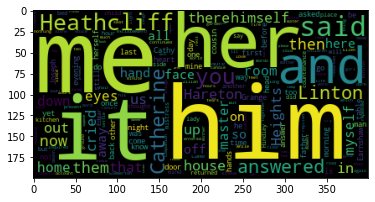

In [3]:
DATA = bronte
freqs = get_frequency_list(DATA)

wcloud = wordcloud.WordCloud().generate_from_frequencies(freqs)
plt.imshow(wcloud)
plt.show()
